### interpolacija

podatki so v neenakomernih time frames, zato jih interpoliramo na korake 0.05

In [1]:
import numpy as np
import pandas as pd

def interpolate_flight(df, time_col="Time", step=0.05):
    orig_time = df[time_col].astype(float).to_numpy()
    start, end = orig_time.min(), orig_time.max()
    
    new_time = np.arange(start, end, step)  #ustvarimo nov čas
    
    interp_data = {"Time": new_time}
    #izbrani = df.drop("Position", axis=1)
    for col in df.columns:
        if col != time_col and np.issubdtype(df[col].dtype, np.number):
            interp_data[col] = np.interp(new_time, orig_time, df[col])
    
    return pd.DataFrame(interp_data)


In [1]:
#df["Position"]

In [56]:
df.drop("Position", axis=1)

,Time,Height above ground [m],X [m],Y [m],Z [m],Opening Angle [°],Stalling Angle Left [°],Stalling Angle Right [°],Roll Angle Left [°],Roll Angle Right [°],...,W11_Speed,W11_Tangent,W11_Turbulence,W11_CleanTan,W11_Cross,W12_Speed,W12_Tangent,W12_Turbulence,W12_CleanTan,W12_Cross
0,4.072,2.930000,0.030000,0.000000,-0.010000,0.000000,-11.500000,-11.500000,0.000000,0.000000,...,1.4,1.180000,0.02,1.180000,0.230000,1.700000,1.360000,0.360000,1.360000,0.770000
1,4.122,2.907273,0.360808,0.002525,-0.070606,1.287879,-11.257576,-12.045455,-0.284091,1.489646,...,1.4,1.172424,0.02,1.172424,0.232525,1.674747,1.332222,0.387778,1.332222,0.752323
2,4.172,2.884545,0.691616,0.005051,-0.131212,2.575758,-11.015152,-12.590909,-0.568182,2.979293,...,1.4,1.164848,0.02,1.164848,0.235051,1.649495,1.304444,0.415556,1.304444,0.734646
3,4.222,2.861818,1.022424,0.007576,-0.191818,3.863636,-10.772727,-13.136364,-0.852273,4.468939,...,1.4,1.157273,0.02,1.157273,0.237576,1.624242,1.276667,0.443333,1.276667,0.716970
4,4.272,2.839500,1.391500,0.010500,-0.257500,5.310000,-10.383750,-13.612300,-1.177550,5.900650,...,1.4,1.150000,0.02,1.150000,0.240000,1.600000,1.250000,0.470000,1.250000,0.700000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
152,11.672,0.795000,184.955000,-4.240000,-110.195000,11.700000,-5.637000,-12.184000,5.396000,-11.071000,...,0.8,0.630000,0.05,0.630000,0.450000,1.500000,1.180000,0.020000,1.180000,0.610000
153,11.722,0.560625,186.179375,-4.303125,-111.180000,10.450000,-8.896375,-14.434000,3.738688,-10.568875,...,0.8,0.630000,0.05,0.630000,0.450000,1.500000,1.180000,0.020000,1.180000,0.610000
154,11.772,0.320000,187.407500,-4.375000,-112.173750,9.200000,-12.156375,-16.685250,2.080250,-10.065750,...,0.8,0.630000,0.05,0.630000,0.450000,1.500000,1.180000,0.020000,1.180000,0.610000
155,11.822,0.137500,188.613437,-4.436250,-113.138437,8.075000,-15.354406,-18.892469,0.454906,-9.572688,...,0.8,0.630000,0.05,0.630000,0.450000,1.500000,1.180000,0.020000,1.180000,0.610000


In [3]:
import os
import pandas as pd

folder_path = r'C:\Users\vsi\Desktop\ijs\smucarski_skoki\project\simulation\2024_03_Planica_12_winds\cleaned'
new_folder = os.path.join(folder_path, "normalized")

for filename in os.listdir(folder_path):
    if filename.endswith('.csv'):
        file_path = os.path.join(folder_path, filename)
        df = pd.read_csv(file_path)
        # Remove the single pre-flight record once, before temporal resampling.
        df = df.iloc[1:].reset_index(drop=True)

        # primer
        interp_df = interpolate_flight(df, time_col="Time", step=0.05)
        #print(interp_df.head())
        cleaned_filename = os.path.splitext(filename)[0] + "_normalized.csv"
        cleaned_path = os.path.join(new_folder, cleaned_filename)
        interp_df.to_csv(cleaned_path, index=False)

In [2]:
import os
import pandas as pd

folder_path = r'C:\Users\vsi\Desktop\ijs\smucarski_skoki\project\simulation\2024_03_Planica_12_winds\cleaned'
new_folder = os.path.join(folder_path, "normalized")
filename = "average_flight.csv"

df = pd.read_csv(filename)
# This historical average file still contains a pre-flight first row; remove it once.
df = df.iloc[1:].reset_index(drop=True)

# primer
interp_df = interpolate_flight(df, time_col="Time", step=0.05)
cleaned_filename = os.path.splitext(filename)[0] + "_normalized.csv"
cleaned_path = os.path.join(new_folder, cleaned_filename)
interp_df.to_csv(cleaned_path, index=False)

In [4]:
print(f"Processing file: {filename}")
print(df.columns)

Processing file: normalized.zip
Index(['Position', 'Height above ground [m]', 'Time', 'X [m]', 'Y [m]',
       'Z [m]', 'Opening Angle [°]', 'Stalling Angle Left [°]',
       'Stalling Angle Right [°]', 'Roll Angle Left [°]',
       'Roll Angle Right [°]', 'Yaw Angle Left [°]', 'Yaw Angle Right [°]',
       'Speed hor. [km/h]', 'Speed vert. [km/h]', 'Speed resulting [km/h]',
       'W1_Speed', 'W1_Tangent', 'W1_Turbulence', 'W1_CleanTan', 'W1_Cross',
       'W2_Speed', 'W2_Tangent', 'W2_Turbulence', 'W2_CleanTan', 'W2_Cross',
       'W3_Speed', 'W3_Tangent', 'W3_Turbulence', 'W3_CleanTan', 'W3_Cross',
       'W4_Speed', 'W4_Tangent', 'W4_Turbulence', 'W4_CleanTan', 'W4_Cross',
       'W5_Speed', 'W5_Tangent', 'W5_Turbulence', 'W5_CleanTan', 'W5_Cross',
       'W6_Speed', 'W6_Tangent', 'W6_Turbulence', 'W6_CleanTan', 'W6_Cross',
       'W7_Speed', 'W7_Tangent', 'W7_Turbulence', 'W7_CleanTan', 'W7_Cross',
       'W8_Speed', 'W8_Tangent', 'W8_Turbulence', 'W8_CleanTan', 'W8_Cross',
      

In [5]:
zones = {
    "takeoff": ["W1", "W2", "W3", "W4"],
    "mid":     ["W5", "W6", "W7", "W8"],
    "landing": ["W9", "W10", "W11", "W12"]
}

wind_features = ["Speed", "Tangent", "Cross", "Turbulence"]

### preprocessing

In [6]:


def preprocess_flight_normalized(df, step=0.05):
    """
    Preprocess a normalized flight dataframe (already interpolated) to generate states (X), observations (Y), and controls (U).
    
    Args:
        df (pd.DataFrame): Normalized flight dataframe (fixed time step).
        step (float): Time step between rows (used for derivatives).
        
    Returns:
        states (np.ndarray): State matrix [time_steps, state_dim].
        observations (np.ndarray): Observation matrix [time_steps, obs_dim].
        controls (np.ndarray): Control matrix [time_steps, control_dim].
    """

    df.columns = df.columns.str.strip()   #izloči imena stolpcev
    # Input is already resampled and contains flight-only rows; retain its first sample.
    
    df = df.ffill().bfill()   #back fill za manjkajoče vrednosti
    
    x = df["X [m]"].to_numpy()   #save values
    y = df["Y [m]"].to_numpy()
    z = df["Z [m]"].to_numpy()
    
    dt = step
    vx = np.gradient(x, dt)   #gradient za hitrost
    vy = np.gradient(y, dt)
    vz = np.gradient(z, dt)


    states = np.stack([x, y, z, vx, vy, vz], axis=1)   #zgradimo state vector X
    

    roll = df.get("Roll Angle Left [°]", pd.Series([0]*len(x))).to_numpy()
    yaw = df.get("Yaw Angle Left [°]", pd.Series([0]*len(x))).to_numpy()
    speed = np.sqrt(vx**2 + vy**2 + vz**2)
    
    observations = np.stack([x, y, z, roll, yaw, speed], axis=1)   #zgradimo observation vector Y

    zone_feature_avgs = []
    

    for feature in wind_features:
        for zone, sensors in zones.items():
            cols = [f"{sensor}_{feature}" for sensor in sensors if f"{sensor}_{feature}" in df.columns]
            avg_feature = df[cols].mean(axis=1).to_numpy()
            zone_feature_avgs.append(avg_feature)
    
    controls = np.stack(zone_feature_avgs, axis=1)  # shape: (time_steps, 12)
    
    return states, observations, controls


#### preverjanje

določiš katere spremenljivke bodo imele katero vlogo v ssm

In [7]:
import os
import pandas as pd
import numpy as np

normalized_folder = r'C:\Users\vsi\Desktop\ijs\smucarski_skoki\project\simulation\2024_03_Planica_12_winds\cleaned\normalized'
combined_output = os.path.join(normalized_folder, "combined_dataset.npz")
file_names = []

X_list, Y_list, U_list = [], [], []

for filename in os.listdir(normalized_folder):
    if filename.endswith('.csv'):
        file_path = os.path.join(normalized_folder, filename)
        df = pd.read_csv(file_path)

        X_state, Y_obs, U_ctrl = preprocess_flight_normalized(df)

        X_list.append(X_state)
        Y_list.append(Y_obs)
        U_list.append(U_ctrl)
        file_names.append(filename)

        print(f"Processed {filename} -> X:{X_state.shape}, Y:{Y_obs.shape}, U:{U_ctrl.shape}")

# Save combined dataset
np.savez(combined_output, X=np.array(X_list, dtype=object), Y=np.array(Y_list, dtype=object), U=np.array(U_list, dtype=object))
print(f"\nCombined dataset saved to {combined_output}")


Processed 999_999_Jumper_Anon_ANO_1_20240409-102625_C_OfficialResults_cleaned_normalized.csv -> X:(135, 6), Y:(135, 6), U:(135, 12)
Processed 999_999_Jumper_Anon_ANO_1_20240409-102742_C_OfficialResults_cleaned_normalized.csv -> X:(131, 6), Y:(131, 6), U:(131, 12)
Processed 999_999_Jumper_Anon_ANO_1_20240409-102831_C_OfficialResults_cleaned_normalized.csv -> X:(145, 6), Y:(145, 6), U:(145, 12)
Processed 999_999_Jumper_Anon_ANO_1_20240409-102832_C_OfficialResults_cleaned_normalized.csv -> X:(139, 6), Y:(139, 6), U:(139, 12)
Processed 999_999_Jumper_Anon_ANO_1_20240409-102833_C_OfficialResults_cleaned_normalized.csv -> X:(136, 6), Y:(136, 6), U:(136, 12)
Processed 999_999_Jumper_Anon_ANO_1_20240409-102834_C_OfficialResults_cleaned_normalized.csv -> X:(132, 6), Y:(132, 6), U:(132, 12)
Processed 999_999_Jumper_Anon_ANO_1_20240409-102835_C_OfficialResults_cleaned_normalized.csv -> X:(156, 6), Y:(156, 6), U:(156, 12)
Processed 999_999_Jumper_Anon_ANO_1_20240409-102836_C_OfficialResults_cleane

In [8]:
from sklearn.model_selection import train_test_split
import numpy as np

# Train/test split along time dimension
X_train, X_test, Y_train, Y_test, U_train, U_test = train_test_split(
    X_list, Y_list, U_list, test_size=0.2, random_state=42
)


spraviš v pravo obliko, zaradi lažjega računanja jih spraviš v enotne vektorje

In [9]:
import numpy as np

# Prepare stacked data for system identification
X_t = np.vstack([seq[:-1] for seq in X_train])      # state at time t   
X_next = np.vstack([seq[1:] for seq in X_train])    # state at time t+1  #spustimo 0. da zamaknemo
U_t = np.vstack([u[:-1] for u in U_train])          # control at time t  - matchamo s X_t
Y_t = np.vstack([obs[:-1] for obs in Y_train])      # observation at time t

print(f"X_t: {X_t.shape}, X_next: {X_next.shape}, U_t: {U_t.shape}, Y_t: {Y_t.shape}")


X_t: (22017, 6), X_next: (22017, 6), U_t: (22017, 12), Y_t: (22017, 6)


s pomočjo MNK (metode najmanjšega kvadrata) določimo phi matriko, iz katere ven dobimo A in B matriko

In [10]:
# Build regression matrix
Phi = np.hstack([X_t, U_t])   # [x_t | u_t]...skupaj sestavimo v eno matriko


Theta, _, _, _ = np.linalg.lstsq(Phi, X_next, rcond=None)  #rešitev po MNK (stabilna verzija)
    #output MNK: matrika A in B, reziduali, rank (A in B), singularnosti (vse razen 1. ignoriramo)
    #ponovimo mnk za vektor, za vsako vrstico v output matriki...MNK za matrike

# Extract A and B
state_dim = X_t.shape[1]
control_dim = U_t.shape[1]
A = Theta[:state_dim, :].T   #prvih state_dim vrstic, vsi stolpci
B = Theta[state_dim:, :].T   #the rest (control_dim)

print("A shape:", A.shape)
print("B shape:", B.shape)


A shape: (6, 6)
B shape: (6, 12)


ponovimo isto, samo da se po liniji vplivov premaknemo dol iz x na y, da lahko dobimo še C in D matriki

In [11]:
Phi_y = np.hstack([X_t, U_t])
Theta_y, _, _, _ = np.linalg.lstsq(Phi_y, Y_t, rcond=None)

obs_dim = Y_t.shape[1]
C = Theta_y[:state_dim, :].T
D = Theta_y[state_dim:, :].T

print("C shape:", C.shape)
print("D shape:", D.shape)


C shape: (6, 6)
D shape: (6, 12)


izračunamo dejansko simulacijo

In [12]:
def simulate_trajectory(x0, U_seq, A, B):
    """
    Simulate trajectory using learned A, B.
    x0: initial state (shape: [state_dim])
    U_seq: control inputs (shape: [T, control_dim])
    """
    X_sim = [x0]  #shrani initial state
    for u in U_seq:                     # @...matrix multiplication
        x_next = A @ X_sim[-1] + B @ u  #Zračuna naslednji korak
        X_sim.append(x_next)            #shrani
    return np.array(X_sim)

# Example: take first flight  (spreminjaš 1. [] pri obeh)
x0 = X_test[0][0]      # first sublist first element
U_seq = U_test[0]      # controls for that flight
X_sim = simulate_trajectory(x0, U_seq, A, B)

print("Simulated trajectory shape:", X_sim.shape)


Simulated trajectory shape: (130, 6)


#### eigenvalues / stability za A

2/6 lastnih vrednosti sta po abs. večji od ena, kar lahko pripelje do nestabilnosti. 

In [13]:
import numpy as np
from scipy.linalg import schur, rsf2csf, ordqz

def project_A_schur(A, target=0.98):
    # Real Schur: A = Q R Q^T, R is quasi-upper-triangular with 1x1 (real) and 2x2 (complex pairs)
    R, Q = schur(A, output='real')
    n = R.shape[0]
    i = 0
    while i < n:
        if i < n-1 and abs(R[i+1, i]) > 1e-12:
            # 2x2 block (complex conjugate pair)
            block = R[i:i+2, i:i+2]
            eigs = np.linalg.eigvals(block)
            maxmag = np.max(np.abs(eigs))
            if maxmag > target:
                scale = target / maxmag
                R[i:i+2, i:i+2] *= scale
            i += 2
        else:
            # 1x1 block
            val = R[i, i]
            mag = abs(val)
            if mag > target and mag > 0:
                R[i, i] = val * (target / mag)
            i += 1
    A_proj = Q @ R @ Q.T
    return A_proj

# usage
A_stable = project_A_schur(A, target=0.98)


Po MNK prilagodimo tudi B matriko in sicer x_t+1 ≈ A_stable * x_t + B * u_t + b

In [14]:
M = X_next - X_t @ A_stable.T
U_new = np.hstack([U_t, np.ones((U_t.shape[0],1))])

#rešimo sistem U_new * W ≈ M  kjer je W...(m+1, n)
W, *_ = np.linalg.lstsq(U_new, M, rcond=None)

B_new = W[:-1, :].T
b_new = W[-1, :]

In [15]:
def simulate(A, B, b, x0, U_seq):
    X = [x0]
    for u in U_seq:
        X.append(A @ X[-1] + B @ u + b)
    return np.array(X)

In [16]:
# Example: take first flight  (spreminjaš 1. [] pri obeh)
x0 = X_train[1][0]      # first sublist first element
U_seq = U_train[1]      # controls for that flight
X_sim = simulate(A_stable, B_new, b_new, x0, U_seq)

print("Simulated trajectory shape:", X_sim.shape)

Simulated trajectory shape: (137, 6)


##### shranjevanje to share

In [17]:
step = 0.05
num_steps = X_state.shape[0]
time_vector = np.arange(num_steps) * step

In [ ]:
import numpy as np

# Example matrices
np.savez("ssm_data.npz", 
     A=A, 
     B=B, 
     C=C, 
     D=D, 
     X_sim=X_sim, 
     U=U_seq, 
     time=time_vector)


### plotting

##### functions za napako

In [18]:
def point_segment_distance(p, a, b):
    """Distance from point p to segment a-b, and projection point"""
    ap = p-a
    ab = b-a
    denom = np.dot(ab, ab)
    if denom == 0:
        return np.linalg.norm(p-a), a
    t = np.dot(ap, ab) / denom #produkt deljen z normo
    t = np.clip(t, 0, 1)
    proj = a + t* ab
    return np.linalg.norm(p-proj), proj

In [19]:
def curve_projection_distance(curve1, curve2):
    """Mean distance from points in curve1 to curve2's segments"""
    distances = []
    for p in curve1:
        min_dist = float("inf")
        for i in range(len(curve2) - 1):
            dist, _ = point_segment_distance(p, curve2[i], curve2[i + 1])
            if dist < min_dist:
                min_dist = dist
        distances.append(min_dist)
    return np.mean(distances)

In [20]:
def bidirectional_curve_distance(curve_a, curve_b):
    """Symetric bidirectionall mean projection distance"""
    d1 = curve_projection_distance(curve_a, curve_b)
    d2 = curve_projection_distance(curve_b, curve_a)
    return (d1 + d2) / 2

In [21]:
def curve_length (curve):
    return np.sum(np.linalg.norm(np.diff(curve, axis=0), axis=1))

def penalized_bidirectional_distance(curve_a, curve_b, length_weight = 0.5):
    shape_dist = bidirectional_curve_distance(curve_a, curve_b)
    len_a = curve_length(curve_a)
    len_b = curve_length(curve_b)
    length_diff = abs(len_a - len_b)
    return shape_dist + length_weight * length_diff

In [22]:
from scipy.spatial import cKDTree

def penalized_bidirectional_distance(A, B, penalty_factor=0.5):
    tree_A = cKDTree(A)
    tree_B = cKDTree(B)

    dist_A_to_B, _ = tree_B.query(A)
    dist_B_to_A, _ = tree_A.query(B)

    mean_A_to_B = np.mean(dist_A_to_B)
    mean_B_to_A = np.mean(dist_B_to_A)

    return mean_A_to_B + penalty_factor * mean_B_to_A


##### code

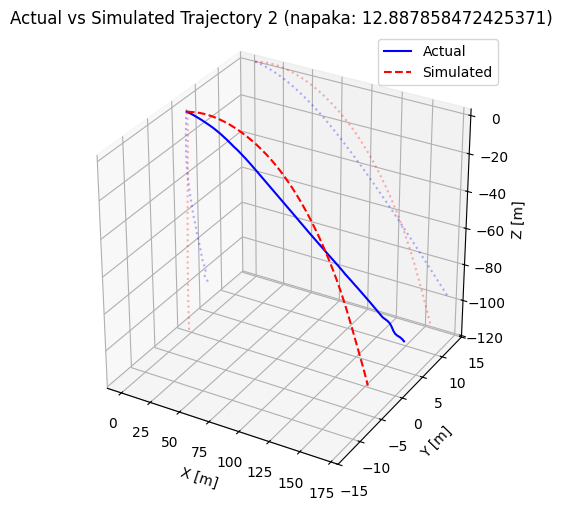

In [23]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import math

    #(spreminjaš 1. [] v 1. vrstici)
actual = X_test[0][:, :3]   #vzame X,Y,Z iz [x, y, z, vx, vy, vz]
sim = X_sim[:, :3]          # same iz simulacije

Xa = actual[:,0]
Ya = actual[:,1]
Za = actual[:,2]

Xs = sim[:,0]
Ys = sim[:,1]
Zs = sim[:,2]

fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111, projection='3d')

ax.plot3D(Xa, Ya, Za, label="Actual", color="blue")
ax.plot3D(Xs, Ys, Zs, label="Simulated", color="red", linestyle="--")


# Ground projections
ax.plot(Xa, 15, Za, color="blue", alpha=0.3, linestyle=':')
ax.plot(Xs, 15, Zs, color="red", alpha=0.3, linestyle=':')


ax.plot(0, Ya, Za, color="blue", alpha=0.3, linestyle=':')
ax.plot(0, Ys, Zs, color="red", alpha=0.3, linestyle=':')


napaka = penalized_bidirectional_distance(actual, sim, 0.5)


ax.set_title(f"Actual vs Simulated Trajectory 2 (napaka: {napaka})")
ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.legend()
ax.set_box_aspect([1,1,1])
ax.set_ylim(-15, 15)

plt.legend()
plt.tight_layout()
plt.show()


#### loop (average napaka:  standardna 26.051993007375483, normalizirana 15.286873113599004)

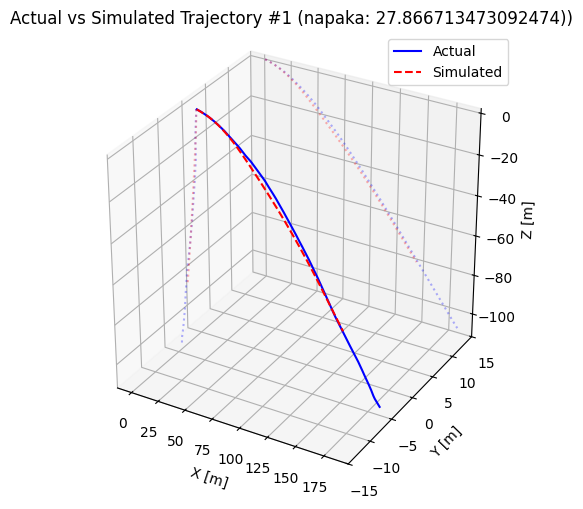

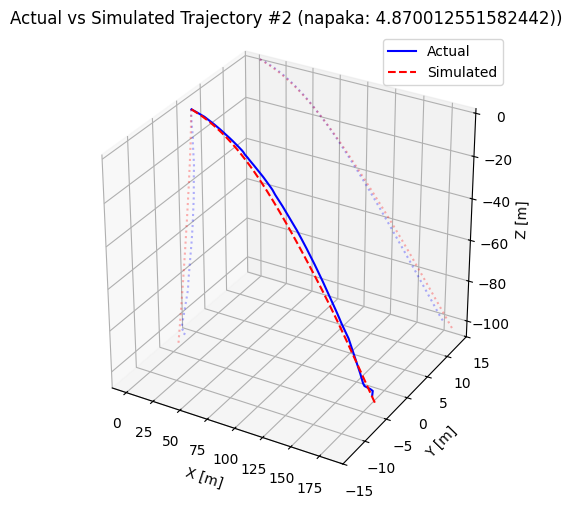

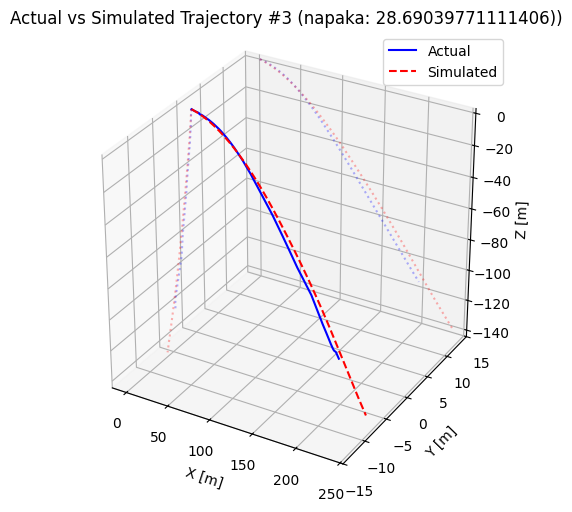

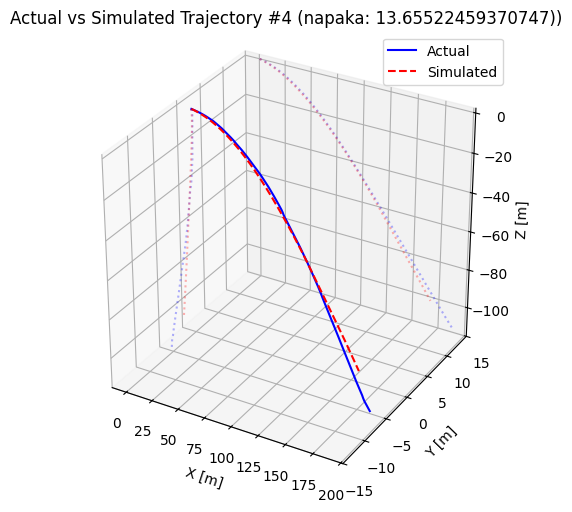

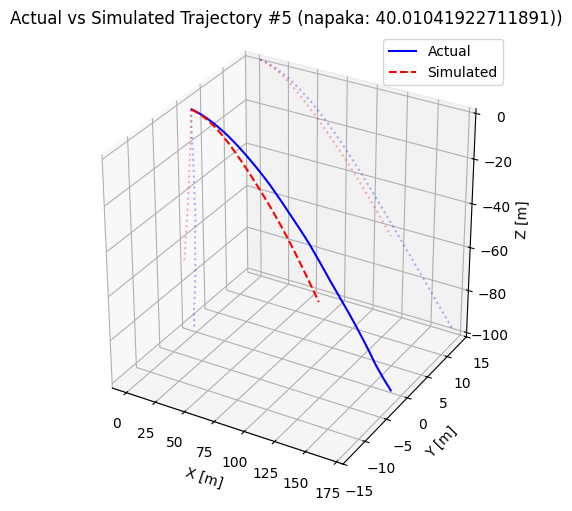

...

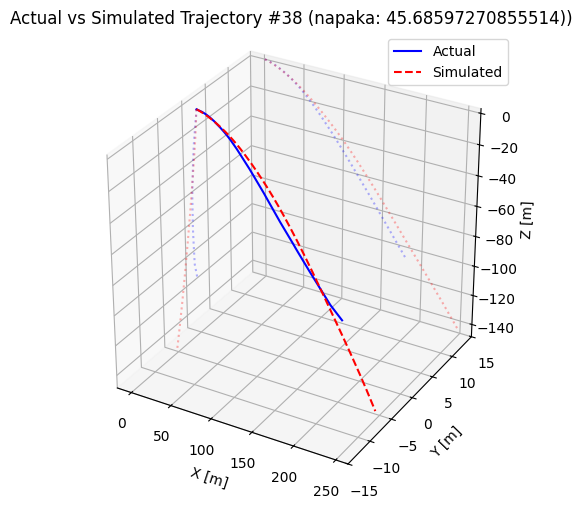

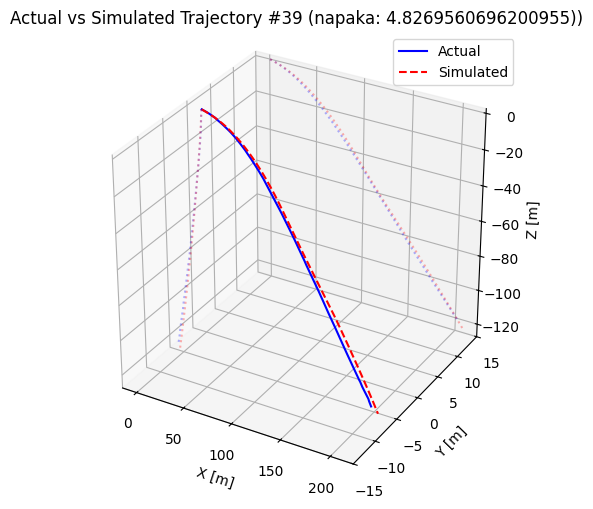

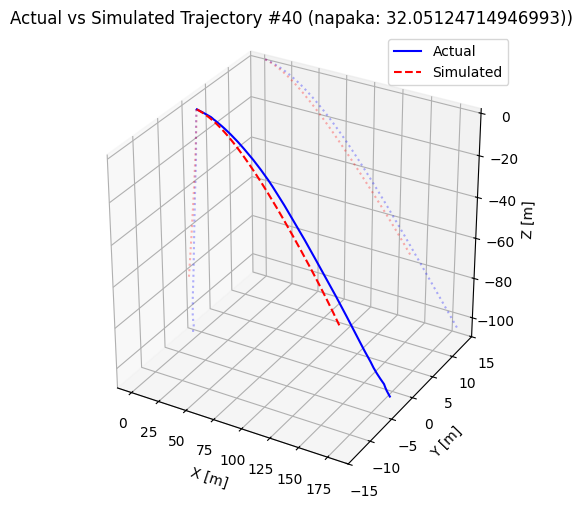

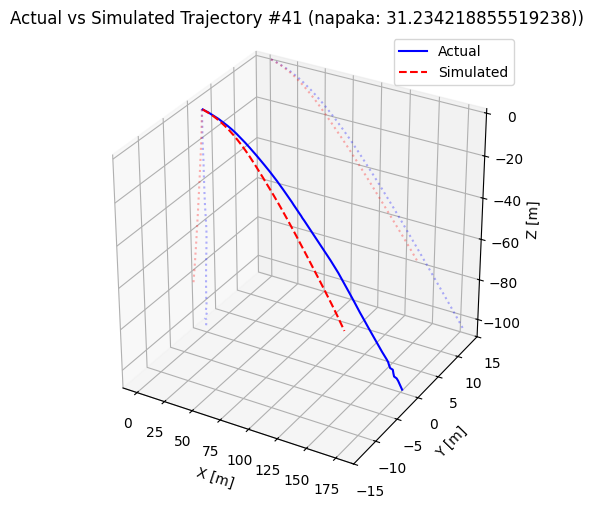

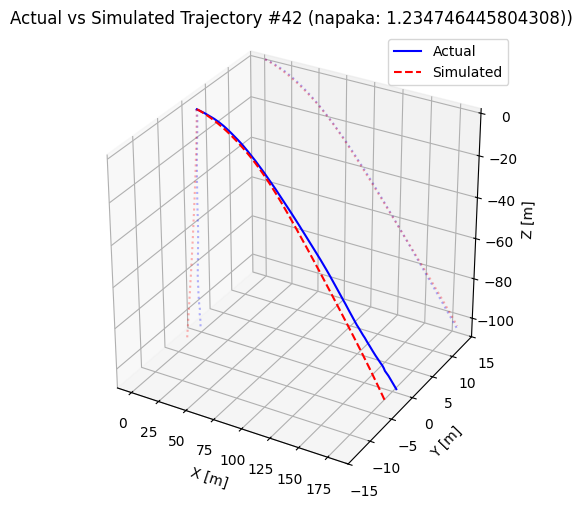

23.286850052810358


In [90]:

save_dir = "plots/normalized_SSM"
os.makedirs(save_dir, exist_ok=True)

napake = []

for idx in range(len(X_test)):

    jump_idx = idx

    x0 = X_train[jump_idx][0]    #0...std in 1...norm 
    U_seq = U_train[jump_idx]      # controls for that flight
    #X_sim = simulate(A_stable, B_new, b_new, x0, U_seq)
    X_sim = simulate_trajectory(x0, U_seq, A, B)


    actual = X_train[jump_idx][:, :3]
    sim = X_sim[:, :3]


    Xa = actual[:,0]
    Ya = actual[:,1]
    Za = actual[:,2]

    Xs = sim[:,0]
    Ys = sim[:,1]
    Zs = sim[:,2]

    fig = plt.figure(figsize=(8, 5))
    ax = fig.add_subplot(111, projection='3d')

    ax.plot3D(Xa, Ya, Za, label="Actual", color="blue")
    ax.plot3D(Xs, Ys, Zs, label="Simulated", color="red", linestyle="--")


    # Ground projections
    ax.plot(Xa, 15, Za, color="blue", alpha=0.3, linestyle=':')
    ax.plot(Xs, 15, Zs, color="red", alpha=0.3, linestyle=':')


    ax.plot(0, Ya, Za, color="blue", alpha=0.3, linestyle=':')
    ax.plot(0, Ys, Zs, color="red", alpha=0.3, linestyle=':')


    napaka = penalized_bidirectional_distance(actual, sim, 0.5)
    napake.append(napaka)

    ax.set_title(f"Actual vs Simulated Trajectory #{jump_idx + 1} (napaka: {napaka}))")
    ax.set_xlabel("X [m]")
    ax.set_ylabel("Y [m]")
    ax.set_zlabel("Z [m]")
    ax.legend()
    ax.set_box_aspect([1,1,1])
    ax.set_ylim(-15, 15)

    plt.legend()
    plt.tight_layout()

    #name = f"flight_simulation{jump_idx + 1}.png"
    #plt.savefig(os.path.join(save_dir, name), dpi=300)

    plt.show()
    
print(np.average(napake))

In [425]:
napake

[np.float64(26.287029330539863),
 np.float64(51.76582725496253),
 np.float64(8.186951467026958),
 np.float64(9.321143078936228),
 np.float64(8.740702160729558),
 np.float64(61.78382467781044),
 np.float64(47.93858909671987),
 np.float64(3.031908778328905),
 np.float64(33.03981583856822),
 np.float64(30.945820161750312),
 np.float64(4.356069084273992),
 np.float64(5.636431028808276),
 np.float64(23.458659401950104),
 np.float64(7.1086050527378495),
 np.float64(25.896791396935882),
 np.float64(23.494512401035916),
 np.float64(30.916338746539033),
 np.float64(37.59547894604806),
 np.float64(3.6684869538035105),
 np.float64(15.684402767802112),
 np.float64(20.278326581722702),
 np.float64(50.69329768658292),
 np.float64(17.945323735577777),
 np.float64(1.341292882548555),
 np.float64(11.453368899006591),
 np.float64(41.90121908147282),
 np.float64(8.63575376128688),
 np.float64(27.056294822772713),
 np.float64(36.04108455457825),
 np.float64(66.78630940355349),
 np.float64(27.7708940586986

#### dodana simulacija observations-doesn't change much

In [281]:
def simulate_trajectory_with_observations(x0, U_seq, A, B, C, D):
    """
    Simulate state trajectory and corresponding observations.
    
    Args:
        x0: initial state (shape: [state_dim])
        U_seq: control inputs sequence (shape: [T, control_dim])
        A, B: system matrices for state update
        C, D: output matrices for observations
        
    Returns:
        X_sim: simulated states (shape: [T+1, state_dim])
        Y_sim: simulated observations (shape: [T+1, obs_dim])
    """
    X_sim = [x0]
    Y_sim = []
    
    for u in U_seq:
        x_next = A @ X_sim[-1] + B @ u
        X_sim.append(x_next)
        y_next = C @ x_next + D @ u
        Y_sim.append(y_next)
    
    # Convert lists to numpy arrays
    X_sim = np.array(X_sim)              # shape (T+1, state_dim)
    Y_sim = np.array(Y_sim)              # shape (T, obs_dim) (one observation per input)
    
    # For alignment, prepend initial observation at t=0:
    y0 = C @ x0 + D @ U_seq[0]           # or just C @ x0 if no input yet
    Y_sim = np.vstack([y0, Y_sim])       # shape (T+1, obs_dim)
    
    return X_sim, Y_sim

# Usage example:
x0 = X_train[4][0]    # initial state of 5th flight
U_seq = U_train[4]    # controls of 5th flight

X_sim, Y_sim = simulate_trajectory_with_observations(x0, U_seq, A, B, C, D)
print("Simulated states shape:", X_sim.shape)
print("Simulated observations shape:", Y_sim.shape)


Simulated states shape: (129, 6)
Simulated observations shape: (129, 6)


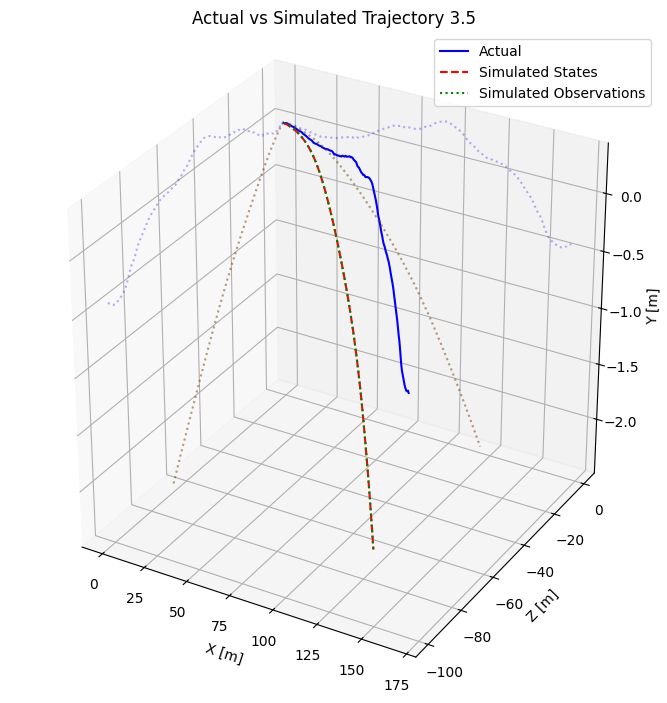

In [282]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Actual trajectory (positions only)
actual = X_train[4][:, :3]   # X, Y, Z from actual states

# Simulated states positions
sim = X_sim[:, :3]          # X, Y, Z from simulated states

# Simulated observations positions
# Assuming Y_sim columns are at least [X, Y, Z, ...], adjust if needed
obs = Y_sim[:, :3]

Xa, Ya, Za = actual[:,0], actual[:,1], actual[:,2]
Xs, Ys, Zs = sim[:,0], sim[:,1], sim[:,2]
Xo, Yo, Zo = obs[:,0], obs[:,1], obs[:,2]

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Plot actual trajectory
ax.plot3D(Xa, Za, Ya, label="Actual", color="blue")

# Plot simulated states trajectory
ax.plot3D(Xs, Zs, Ys, label="Simulated States", color="red", linestyle="--")

# Plot simulated observations trajectory
ax.plot3D(Xo, Zo, Yo, label="Simulated Observations", color="green", linestyle=":")

# Ground projections (X-Z plane)
ax.plot(Xa, 0, Ya, color="blue", alpha=0.3, linestyle=':')
ax.plot(Xs, 0, Ys, color="red", alpha=0.3, linestyle=':')
ax.plot(Xo, 0, Yo, color="green", alpha=0.3, linestyle=':')

# Vertical projections (Z-Y plane)
ax.plot(0, Za, Ya, color="blue", alpha=0.3, linestyle=':')
ax.plot(0, Zs, Ys, color="red", alpha=0.3, linestyle=':')
ax.plot(0, Zo, Yo, color="green", alpha=0.3, linestyle=':')

ax.set_title("Actual vs Simulated Trajectory 3.5")
ax.set_xlabel("X [m]")
ax.set_ylabel("Z [m]")
ax.set_zlabel("Y [m]")
ax.legend()
ax.set_box_aspect([1,1,1])

plt.tight_layout()
plt.show()


## PINN

implementacija PINN (physics-informed neural network...ima vgrajene newtnove zakone and such) s pytorch.
Cilj: izboljšat simulacijo, specifično dolžino skokov. 

In [23]:
import torch
from torch.utils.data import Dataset, DataLoader

class SSMFlightDataset(Dataset):
    def __init__(self, X_t, U_t, X_next):
        self.X_t = torch.tensor(X_t, dtype=torch.float32)
        self.U_t = torch.tensor(U_t, dtype=torch.float32)
        self.X_next = torch.tensor(X_next, dtype=torch.float32)

    def __len__(self):
        return len(self.X_t)

    def __getitem__(self, idx):
        return self.X_t[idx], self.U_t[idx], self.X_next[idx]


In [ ]:
#def wind_force_model(U_t):
#    zones = U_t.view(-1, 3, 4)
#
#    # Aggregate effect across zones
#    speed = zones[:, :, 0].mean(dim=1)
#    tangent = zones[:, :, 1].mean(dim=1)
#    cross = zones[:, :, 2].mean(dim=1)
#    turbulence = zones[:, :, 3].mean(dim=1)
#    
#    # Map to forces
#    lift = 0.5 * rho * area * speed**2 * lift_coeff
#    drag = 0.5 * rho * area * speed**2 * drag_coeff
#    
#    # Tangent wind changes velocity along flight path
#    tangential_force = tangent_coeff * tangent
#    
#    # Cross wind changes sideways velocity
#    cross_force = cross_coeff * cross
#    
#    # Turbulence as noise/disturbance
#    turbulence_force = turbulence_coeff * turbulence
#    
#    return torch.stack([lift, drag, tangential_force, cross_force, turbulence_force], dim=1)

In [24]:
import torch
import torch.nn as nn

class WindForceModel(nn.Module):
    def __init__(self, input_dim=12, output_dim=5):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, output_dim)
        )

    def forward(self, u):
        # Output: [lift, drag, tangential, cross, turbulence]
        return self.net(u)


In [ ]:
#def newtons_loss(x_t, x_next, u_t, m, g, dt):
#    vel_t = x_t[:,3:6]
#    vel_next = x_next[:, 3:6]
#    acc_t = (vel_next - vel_t) / dt
#
#    

In [ ]:
import torch.nn as nn

class PINNModel(nn.Module):
    def __init__(self, state_dim, control_dim, obs_dim, A, B, C, D, m=65.0, g=9.81, dt=0.02):
        super().__init__()
        self.A = torch.tensor(A, dtype=torch.float32, requires_grad=False)      #requires_grad=F...ne treniramo-fiksiramo
        self.B = torch.tensor(B, dtype=torch.float32, requires_grad=False)
        self.C = torch.tensor(C, dtype=torch.float32, requires_grad=False)
        self.D = torch.tensor(D, dtype=torch.float32, requires_grad=False)



        self.state_residual_net = nn.Sequential(
            nn.Linear(state_dim + control_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, state_dim)
        )

        self.obser_residual_net = nn.Sequential(
            nn.Linear(state_dim + control_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, obs_dim)
        )

        self.wind_force_model = WindForceModel(control_dim, output_dim=5)

        self.m = m
        self.g = g
        self.dt = dt

    #def forward(self, x, u):
    #    physics_wind = wind_force_model(u)
    #    physics_state = x @ self.A.T + u @ self.B.T + wind_to_state @ physics_wind.T      #x_{t+1} = A*x_{t} + B*u_{t} + vetrovi
    #    residual_state = self.state_residual_net(torch.cat([x, u], dim=1))      #x in u združi v en vektor
    #    #print(f"physics[0] = {physics[0]} and residual = {residual[0]}")
    #    next_state = physics_state + residual_state
    #
    #    physics_obser = x @ self.C.T + u @ self.D.T       #x_{t+1} = C*x_{t} + D*u_{t}
    #    residual_obser = self.obser_residual_net(torch.cat([x, u], dim=1))      #x in u združi v en vektor
    #    next_obser = physics_obser + residual_obser
    #
    #    return next_state, next_obser


    def forward(self, x, u):
        # Physics-based state prediction
        physics_state = x @ self.A.T + u @ self.B.T
        residual_state = self.state_residual_net(torch.cat([x, u], dim=1))
        next_state = physics_state + residual_state

        # Physics-based observation prediction
        physics_obser = x @ self.C.T + u @ self.D.T
        residual_obser = self.obser_residual_net(torch.cat([x, u], dim=1))
        next_obser = physics_obser + residual_obser

        # -----------------
        # Physics residuals
        # -----------------
        vel = X_t[:, 3:6]  # assuming state = [pos_x, pos_y, vel_x, vel_y, ...]
        vel_next = next_state[:, 3:6]
        accel_pred = (vel_next - vel) / self.dt


     # drag + gravity physics



#sestavimo lastnosti vetra 
        zoned = U_t.view(-1, 3, 4)
        speed = zoned[:, :, 0]
        tangent = zoned[:, :, 1]
        cross = zoned[:, :, 2]
        turbulence= zoned[:, :, 3]

        wind_vectors = torch.stack([
            speed * tangent,    #x
            speed * cross,      #y
            turbulence          #z
        ], dim=-1)

        weights = torch.tensor([0.5, 0.3, 0.2], device=U_t.device)  # stronger weight on early zone
        wind = (wind_vectors * weights[None, :, None]).sum(dim=1)




        mass = 65.0  # kg
        v_rel = vel - wind
        Cd, rho, A_cross = 0.5, 1.225, 0.5

        v_rel = vel - wind
        drag_force = -0.5 * rho * Cd * A_cross * torch.norm(v_rel, dim=1, keepdim=True) * v_rel
        gravity_force = torch.tensor([0, 0, -mass * self.g], dtype=torch.float32).unsqueeze(0)

        forces = self.wind_force_model(u)
        lift, drag, tangential_force, cross_force, turbulence_force = torch.unbind(forces, dim=1)

        #gravity_force = torch.stack([torch.zeros_like(lift), torch.zeros_like(lift), -self.m * self.g * torch.ones_like(lift)], dim=1)

        net_force = torch.stack([
            tangential_force - drag + cross_force,  # x
            cross_force,                            # y
            lift - drag + turbulence_force          # z
        ], dim=1) + gravity_force

        accel_physics = total_force / self.m

        total_force = aero_force + gravity_force


        #if inference:
        #    # Only detach & convert here
        #    return (
        #        next_state.detach().cpu().numpy(),
        #        next_obser.detach().cpu().numpy(),
        #        accel_pred.detach().cpu().numpy(),
        #        accel_physics.detach().cpu().numpy()
        #    )
        #else:
        return next_state, next_obser, accel_pred, accel_physics



In [30]:

state_dim = A.shape[1]
control_dim = B.shape[1]
obs_dim = C.shape[0]

model = PINNModel(state_dim, control_dim, obs_dim, A, B, C, D)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

lambda_phys = 0.1
epochs = 400

flight_losses = [[] for _, _ in enumerate(zip(X_train, U_train))]

for epoch in range(epochs):
    total_loss = 0
    for idx, (X_seq, U_seq) in enumerate(zip(X_train, U_train)):
        flight_losses[idx] = []
        X_t = torch.tensor(X_seq[:-1], dtype=torch.float32)
        X_next = torch.tensor(X_seq[1:], dtype=torch.float32)
        U_t = torch.tensor(U_seq[:-1], dtype=torch.float32)

        Y_next = X_next[:, :obs_dim]

        optimizer.zero_grad()

        pred_next_state, pred_next_obser, accel_pred, accel_physics = model(X_t, U_t)

        loss_state = loss_fn(pred_next_state, X_next)
        loss_obser = loss_fn(pred_next_obser, Y_next)
        loss_physics = loss_fn(accel_pred, accel_physics)
        loss = loss_state + loss_obser + lambda_phys * loss_physics

        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        napaka = loss.item()
        flight_losses[idx].append(napaka)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch}, Total Loss: {total_loss:.4f}, State Loss: {loss_state.item():.4f}, Obs Loss: {loss_obser.item():.4f}, Physics Loss: {loss_physics.item():.4f}")


Epoch 9, Total Loss: 3805.0560, State Loss: 0.2742, Obs Loss: 7.3146, Physics Loss: 137.8579
Epoch 19, Total Loss: 1961.6507, State Loss: 0.2746, Obs Loss: 1.1337, Physics Loss: 107.9244
Epoch 29, Total Loss: 1487.7608, State Loss: 0.2606, Obs Loss: 0.3847, Physics Loss: 36.7968
Epoch 39, Total Loss: 1248.4306, State Loss: 0.2508, Obs Loss: 0.2957, Physics Loss: 2.8870
Epoch 49, Total Loss: 1201.2182, State Loss: 0.2592, Obs Loss: 0.8488, Physics Loss: 23.1697
Epoch 59, Total Loss: 1054.3892, State Loss: 0.2613, Obs Loss: 0.2786, Physics Loss: 31.3399
Epoch 69, Total Loss: 1077.3821, State Loss: 0.2621, Obs Loss: 0.2977, Physics Loss: 44.7161
Epoch 79, Total Loss: 1058.5575, State Loss: 0.2520, Obs Loss: 0.3371, Physics Loss: 6.2581
Epoch 89, Total Loss: 1183.3448, State Loss: 0.2538, Obs Loss: 0.2452, Physics Loss: 39.7437
Epoch 99, Total Loss: 898.4395, State Loss: 0.2509, Obs Loss: 0.2176, Physics Loss: 4.6732
Epoch 109, Total Loss: 984.8327, State Loss: 0.2499, Obs Loss: 0.3176, Ph

In [31]:
mean_losses = [np.mean(lst) for lst in flight_losses]
bad_ids = np.argsort(mean_losses)[-5:]  # worst flights
bad_ids


array([128, 103,  59,  40,  27])

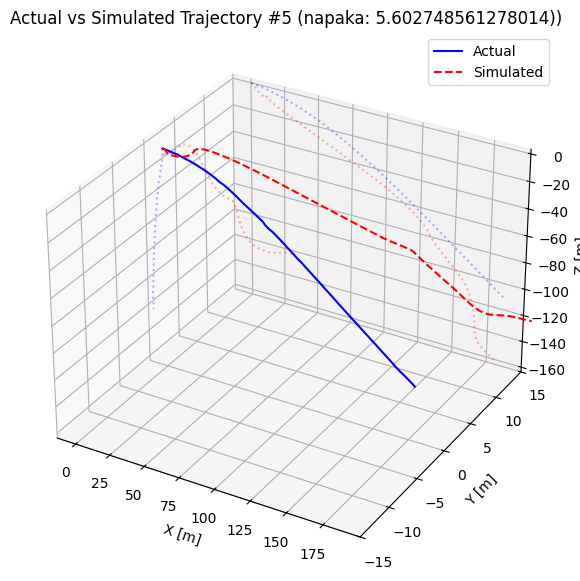

In [39]:
import matplotlib.pyplot as plt

# Pick a jump from TEST set
jump_idx = 4
X_seq_test = X_test[jump_idx]
U_seq_test = U_test[jump_idx]

# Start with the first actual state from the test jump (tensor)
x_pred = [torch.tensor(X_seq_test[0], dtype=torch.float32)]
y_pred = []

# Free-running prediction
for u in U_seq_test[:-1]:
    u_tensor = torch.tensor(u, dtype=torch.float32).unsqueeze(0)
    x_tensor = x_pred[-1].unsqueeze(0)

    next_state, next_obser, _, _  = model(x_tensor, u_tensor)
    x_pred.append(next_state.squeeze(0).detach())  # still tensor
    y_pred.append(next_obser.squeeze(0).detach())

# Convert to numpy for plotting
x_pred_np = torch.stack(x_pred).numpy()
y_pred_np = torch.stack(y_pred).numpy()

# Extract XYZ from true and predicted
true_xyz = np.array(X_seq_test)[:, :3]
pred_xyz = x_pred_np[:, :3]

napaka = penalized_bidirectional_distance(actual, sim, 0.5)


# Plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')


Xa, Ya, Za = true_xyz[:, 0], true_xyz[:, 1], true_xyz[:, 2]
Xs, Ys, Zs = pred_xyz[:, 0], pred_xyz[:, 1], pred_xyz[:, 2]


ax.plot(Xa, Ya, Za, label="Actual", color="blue")
ax.plot(Xs, Ys, Zs, label="Simulated", color="red", linestyle="--")

# Ground projections
ax.plot(Xa, 15, Za, color="blue", alpha=0.3, linestyle=':')
ax.plot(Xs, 15, Zs, color="red", alpha=0.3, linestyle=':')


ax.plot(0, Ya, Za, color="blue", alpha=0.3, linestyle=':')
ax.plot(0, Ys, Zs, color="red", alpha=0.3, linestyle=':')

#napake.append(napaka)



ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.set_title(f"Actual vs Simulated Trajectory #{jump_idx + 1} (napaka: {napaka}))")
ax.set_ylim(-15, 15)
ax.legend()
plt.show()


In [334]:
import torch
import torch.nn as nn
import numpy as np
import random

state_dim = A.shape[1]
control_dim = B.shape[1]
obs_dim = C.shape[0]

model = PINNModel(state_dim, control_dim, obs_dim, A, B, C, D)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

epochs = 400
initial_rollout_len = 5    # start small
rollout_growth = 5         # increase every 50 epochs
teacher_forcing_prob = 0.7 # fraction of sequences trained in teacher forcing

for epoch in range(epochs):
    total_loss = 0.0

    # Gradually increase rollout length
    rollout_len = initial_rollout_len + (epoch // 50) * rollout_growth

    for X_seq, U_seq in zip(X_train, U_train):
        if len(X_seq) <= 1:  # skip invalid sequences
            continue

        # Decide if this sequence will be teacher-forcing or rollout
        if random.random() < teacher_forcing_prob:
            # ----- Teacher forcing (vectorized & fast) -----
            X_t = torch.tensor(X_seq[:-1], dtype=torch.float32)
            X_next = torch.tensor(X_seq[1:], dtype=torch.float32)
            U_t = torch.tensor(U_seq[:-1], dtype=torch.float32)
            Y_next = X_next[:, :obs_dim]

            pred_next_state, pred_next_obser = model(X_t, U_t)

            loss_state = loss_fn(pred_next_state, X_next)
            loss_obser = loss_fn(pred_next_obser, Y_next)
            loss = loss_state + loss_obser

        else:
            # ----- Free-rollout but only up to rollout_len -----
            x_pred = torch.tensor(X_seq[0], dtype=torch.float32).unsqueeze(0)
            seq_loss_state = 0.0
            seq_loss_obs = 0.0
            steps = min(len(X_seq)-1, rollout_len)

            for t in range(steps):
                u_t = torch.tensor(U_seq[t], dtype=torch.float32).unsqueeze(0)
                x_target = torch.tensor(X_seq[t+1], dtype=torch.float32).unsqueeze(0)
                y_target = x_target[:, :obs_dim]

                pred_state, pred_obs = model(x_pred, u_t)

                seq_loss_state += loss_fn(pred_state, x_target)
                seq_loss_obs += loss_fn(pred_obs, y_target)

                # Feed prediction into next step
                x_pred = pred_state.detach()  # stop gradient from exploding

            loss = (seq_loss_state + seq_loss_obs) / steps

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Total Loss: {total_loss:.4f}, Rollout Len: {rollout_len}")


Epoch 1, Total Loss: 38478.9883, Rollout Len: 5
Epoch 2, Total Loss: 23845.0072, Rollout Len: 5
Epoch 3, Total Loss: 15517.9937, Rollout Len: 5
Epoch 4, Total Loss: 9721.1542, Rollout Len: 5
Epoch 5, Total Loss: 7123.2137, Rollout Len: 5
Epoch 6, Total Loss: 5152.9896, Rollout Len: 5
Epoch 7, Total Loss: 4890.0961, Rollout Len: 5
Epoch 8, Total Loss: 3051.1664, Rollout Len: 5
Epoch 9, Total Loss: 3734.1531, Rollout Len: 5
Epoch 10, Total Loss: 3132.8392, Rollout Len: 5
Epoch 11, Total Loss: 2437.2945, Rollout Len: 5
Epoch 12, Total Loss: 2036.0233, Rollout Len: 5
Epoch 13, Total Loss: 2270.6299, Rollout Len: 5
Epoch 14, Total Loss: 1685.7429, Rollout Len: 5
Epoch 15, Total Loss: 2214.4559, Rollout Len: 5
Epoch 16, Total Loss: 1545.0157, Rollout Len: 5
Epoch 17, Total Loss: 1580.3056, Rollout Len: 5
Epoch 18, Total Loss: 1793.1046, Rollout Len: 5
Epoch 19, Total Loss: 2359.0474, Rollout Len: 5
Epoch 20, Total Loss: 1767.6972, Rollout Len: 5
Epoch 21, Total Loss: 1787.8572, Rollout Len: 

#### napaka by time step

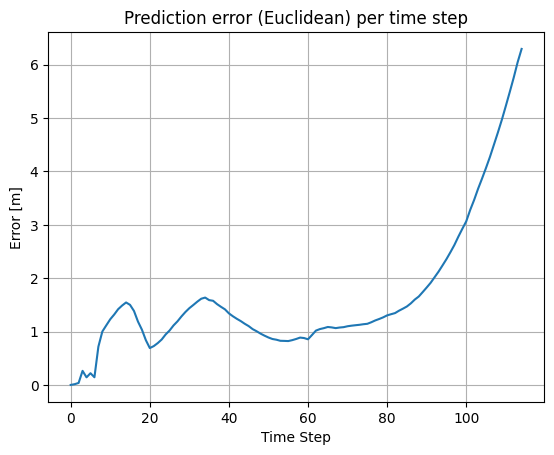

In [329]:
from numpy.linalg import norm

error = norm(pred_xyz - true_xyz, axis=1)

plt.plot(error)
plt.title("Prediction error (Euclidean) per time step")
plt.xlabel("Time Step")
plt.ylabel("Error [m]")
plt.grid(True)
plt.show()


#### loop (average napaka: 15.399636663087282)

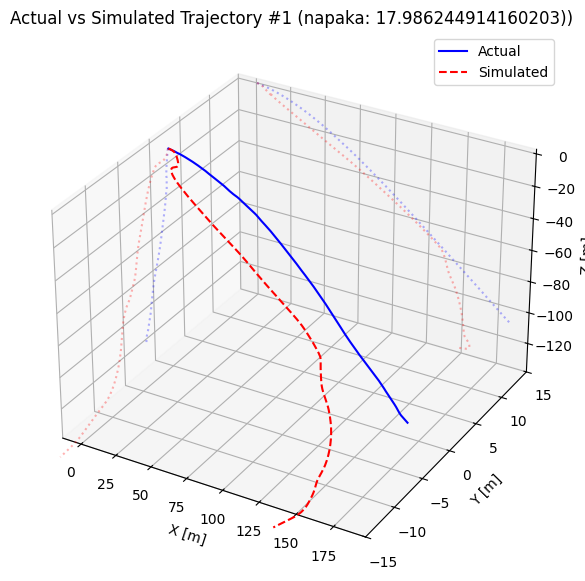

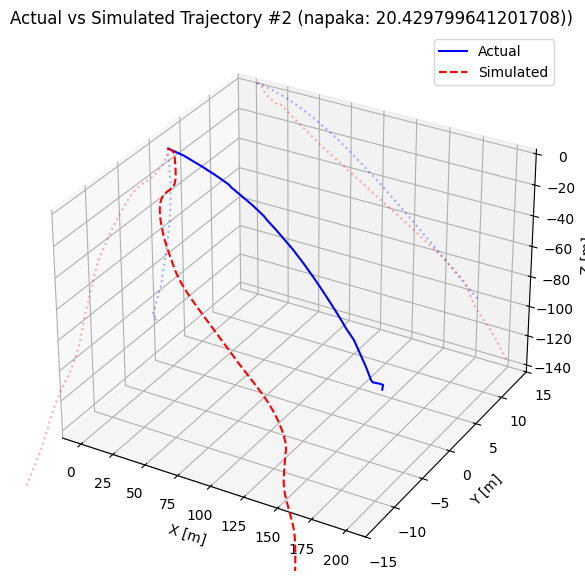

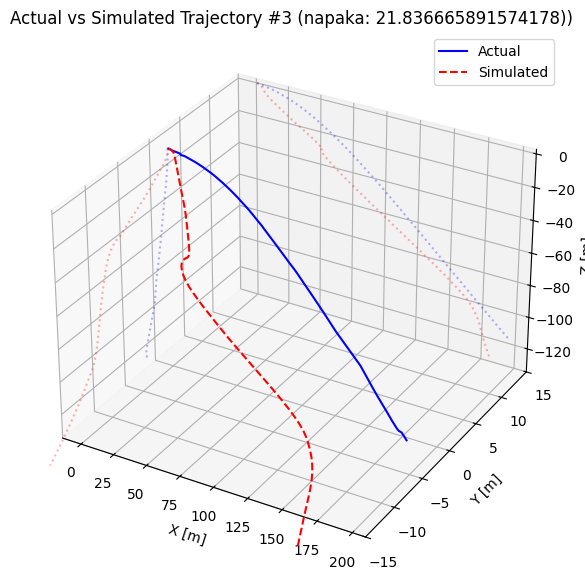

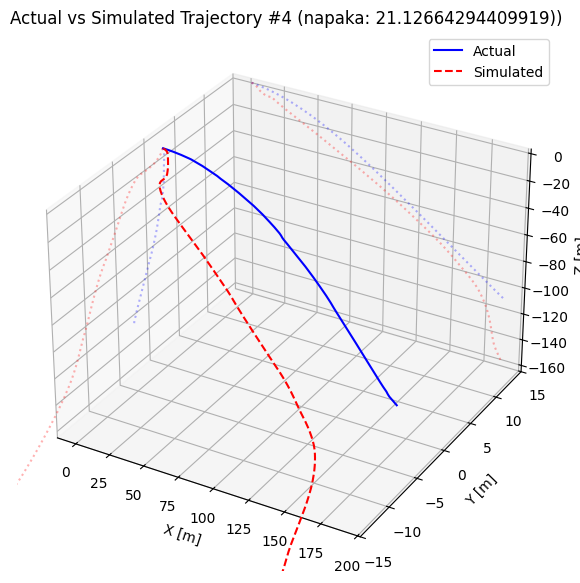

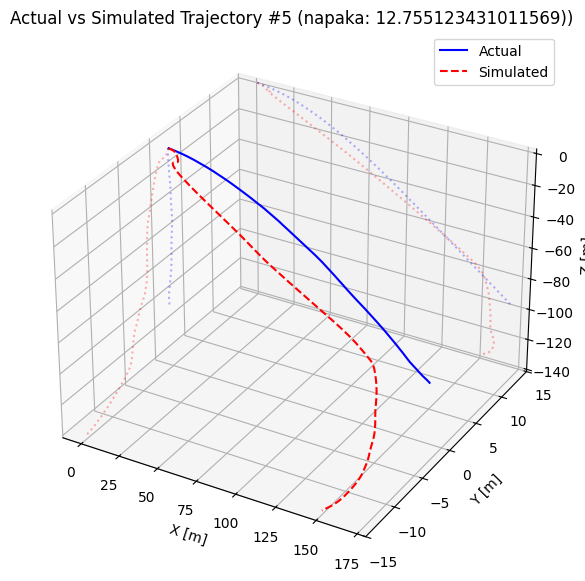

...

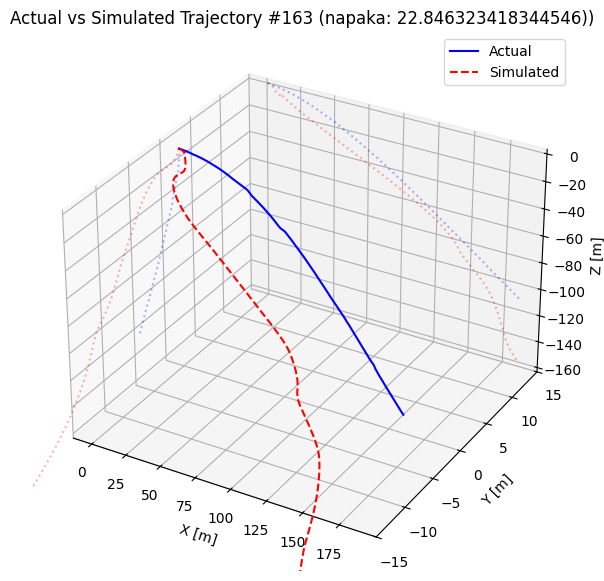

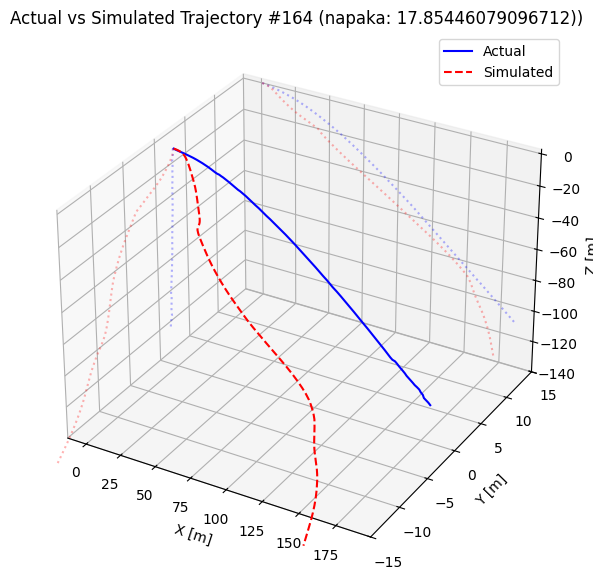

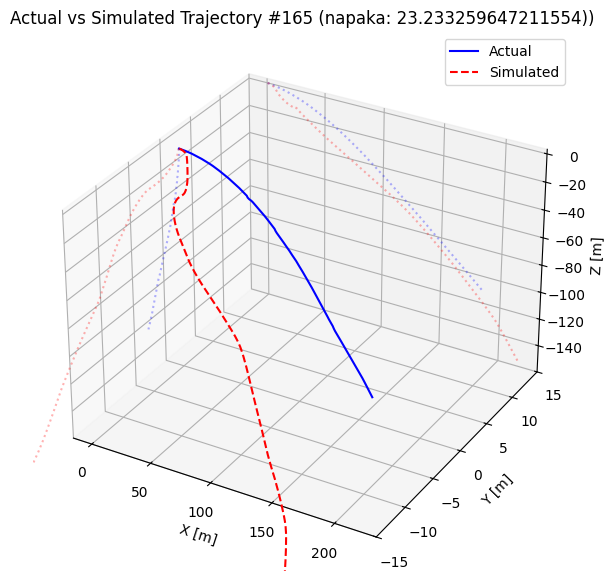

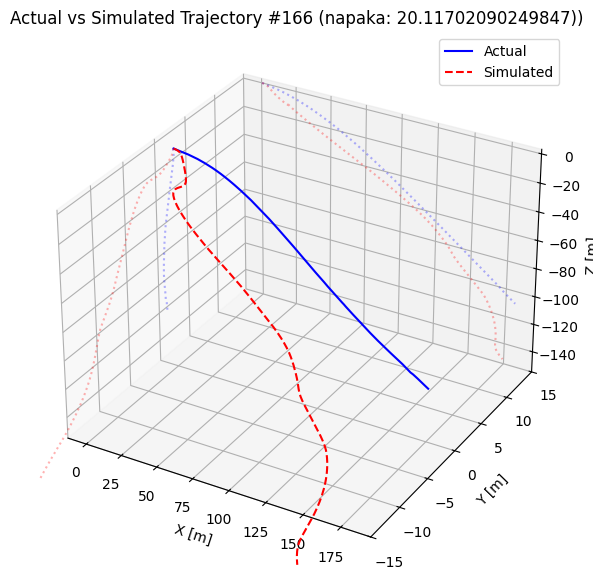

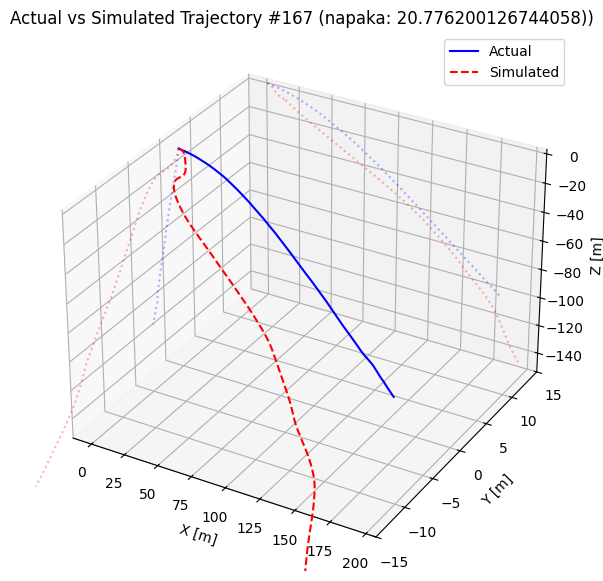

22.44259554961918


In [37]:

#save_dir = "plots/simulated/mirroring"
#os.makedirs(save_dir, exist_ok=True)

napake= []

for idx in range(len(X_train)):
    # Pick a jump from TEST set
    jump_idx = idx
    X_seq_test = X_train[jump_idx]
    U_seq_test = U_train[jump_idx]

    # Start with the first actual state from the test jump (tensor)
    x_pred = [torch.tensor(X_seq_test[0], dtype=torch.float32)]
    y_pred = []

    # Free-running prediction
    for u in U_seq_test[:-1]:
        u_tensor = torch.tensor(u, dtype=torch.float32).unsqueeze(0)
        x_tensor = x_pred[-1].unsqueeze(0)

        next_state, next_obser, _, _ = model(x_tensor, u_tensor)
        x_pred.append(next_state.squeeze(0).detach())  # still tensor
        y_pred.append(next_obser.squeeze(0).detach())

    # Convert to numpy for plotting
    x_pred_np = torch.stack(x_pred).numpy()
    y_pred_np = torch.stack(y_pred).numpy()

    # Extract XYZ from true and predicted
    true_xyz = np.array(X_seq_test)[:, :3]
    pred_xyz = x_pred_np[:, :3]

    # Plot
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')


    Xa = true_xyz[:, 0]
    Ya = true_xyz[:, 1]
    Za = true_xyz[:, 2]

    Xs = pred_xyz[:,0]
    Ys = pred_xyz[:,1]
    Zs = pred_xyz[:,2]

    ax.plot(Xa, Ya, Za, label="Actual", color="blue")
    ax.plot(Xs, Ys, Zs, label="Simulated", color="red", linestyle="--")

    # Ground projections
    ax.plot(Xa, 15, Za, color="blue", alpha=0.3, linestyle=':')
    ax.plot(Xs, 15, Zs, color="red", alpha=0.3, linestyle=':')


    ax.plot(0, Ya, Za, color="blue", alpha=0.3, linestyle=':')
    ax.plot(0, Ys, Zs, color="red", alpha=0.3, linestyle=':')

    napaka = penalized_bidirectional_distance(true_xyz, pred_xyz, 0.5)
    napake.append(napaka)


    ax.set_ylim(-15, 15)
    ax.set_xlabel("X [m]")
    ax.set_ylabel("Y [m]")
    ax.set_zlabel("Z [m]")
    ax.set_title(f"Actual vs Simulated Trajectory #{jump_idx + 1} (napaka: {napaka}))")
    ax.legend()

    name = f"3pinn_flight_simulation{jump_idx + 1}.png"

    #plt.savefig(os.path.join(save_dir, name), dpi=300)

    plt.show()

print(np.average(napake))
    

#### file names

In [ ]:
for i, (pred, truth) in enumerate(zip(y_pred_all, Y_test)):
    error = torch.max(torch.abs(pred - truth)).item()
    if error > 5.0:  # adjust threshold
        print(f"Unstable prediction in test flight {i} from {test_files[i]}")


## emergency thingy

In [91]:
import torch
from torch.utils.data import Dataset, DataLoader

class SSMFlightDataset(Dataset):
    def __init__(self, X_t, U_t, X_next):
        self.X_t = torch.tensor(X_t, dtype=torch.float32)
        self.U_t = torch.tensor(U_t, dtype=torch.float32)
        self.X_next = torch.tensor(X_next, dtype=torch.float32)

    def __len__(self):
        return len(self.X_t)

    def __getitem__(self, idx):
        return self.X_t[idx], self.U_t[idx], self.X_next[idx]

In [93]:
import torch.nn as nn

class PINNModel(nn.Module):
    def __init__(self, state_dim, control_dim, obs_dim, A, B, C, D):
        super().__init__()
        self.A = torch.tensor(A, dtype=torch.float32, requires_grad=False)      #requires_grad=F...ne treniramo-fiksiramo
        self.B = torch.tensor(B, dtype=torch.float32, requires_grad=False)
        self.C = torch.tensor(C, dtype=torch.float32, requires_grad=False)
        self.D = torch.tensor(D, dtype=torch.float32, requires_grad=False)



        self.state_residual_net = nn.Sequential(
            nn.Linear(state_dim + control_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, state_dim)
        )

        self.obser_residual_net = nn.Sequential(
            nn.Linear(state_dim + control_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, obs_dim)
        )

    def forward(self, x, u):
        physics_state = x @ self.A.T + u @ self.B.T       #x_{t+1} = A*x_{t} + B*u_{t}
        residual_state = self.state_residual_net(torch.cat([x, u], dim=1))      #x in u združi v en vektor
        #print(f"physics[0] = {physics[0]} and residual = {residual[0]}")
        next_state = physics_state + residual_state

        physics_obser = x @ self.C.T + u @ self.D.T       #x_{t+1} = C*x_{t} + D*u_{t}
        residual_obser = self.obser_residual_net(torch.cat([x, u], dim=1))      #x in u združi v en vektor
        next_obser = physics_obser + residual_obser

        return next_state, next_obser

In [94]:
flight_losses = [[] for _, _ in enumerate(zip(X_train, U_train))]

state_dim = A.shape[1]
control_dim = B.shape[1]
obs_dim = C.shape[0]

model = PINNModel(state_dim, control_dim, obs_dim, A, B, C, D)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

epochs = 400
for epoch in range(epochs):
    total_loss = 0
    for idx, (X_seq, U_seq) in enumerate(zip(X_train, U_train)):
        flight_losses[idx] = []
        X_t = torch.tensor(X_seq[:-1], dtype=torch.float32)
        X_next = torch.tensor(X_seq[1:], dtype=torch.float32)
        U_t = torch.tensor(U_seq[:-1], dtype=torch.float32)

        Y_next = X_next[:, :obs_dim]

        optimizer.zero_grad()

        pred_next_state, pred_next_obser = model(X_t, U_t)

        loss_state = loss_fn(pred_next_state, X_next)
        loss_obser = loss_fn(pred_next_obser, Y_next)
        loss = loss_state + loss_obser

        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        napaka = loss.item()
        flight_losses[idx].append(napaka)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch}, Total Loss: {total_loss:.4f}, State Loss: {loss_state.item():.4f}, Obs Loss: {loss_obser.item():.4f}")

Epoch 9, Total Loss: 2065.8957, State Loss: 0.0937, Obs Loss: 7.6609
Epoch 19, Total Loss: 992.3238, State Loss: 0.0967, Obs Loss: 0.9557
Epoch 29, Total Loss: 866.2661, State Loss: 0.0922, Obs Loss: 0.3166
Epoch 39, Total Loss: 778.3085, State Loss: 0.0719, Obs Loss: 0.2642
Epoch 49, Total Loss: 706.6105, State Loss: 0.0590, Obs Loss: 0.2230
Epoch 59, Total Loss: 646.9052, State Loss: 0.0738, Obs Loss: 0.4943
Epoch 69, Total Loss: 618.0469, State Loss: 0.0651, Obs Loss: 0.6134
Epoch 79, Total Loss: 585.8944, State Loss: 0.0765, Obs Loss: 0.1719
Epoch 89, Total Loss: 582.8348, State Loss: 0.0624, Obs Loss: 0.1850
Epoch 99, Total Loss: 535.5052, State Loss: 0.0560, Obs Loss: 0.2007
Epoch 109, Total Loss: 530.2277, State Loss: 0.0489, Obs Loss: 0.1707
Epoch 119, Total Loss: 512.1439, State Loss: 0.0611, Obs Loss: 0.2307
Epoch 129, Total Loss: 507.8616, State Loss: 0.0485, Obs Loss: 0.2189
Epoch 139, Total Loss: 499.9159, State Loss: 0.0462, Obs Loss: 0.1558
Epoch 149, Total Loss: 479.647

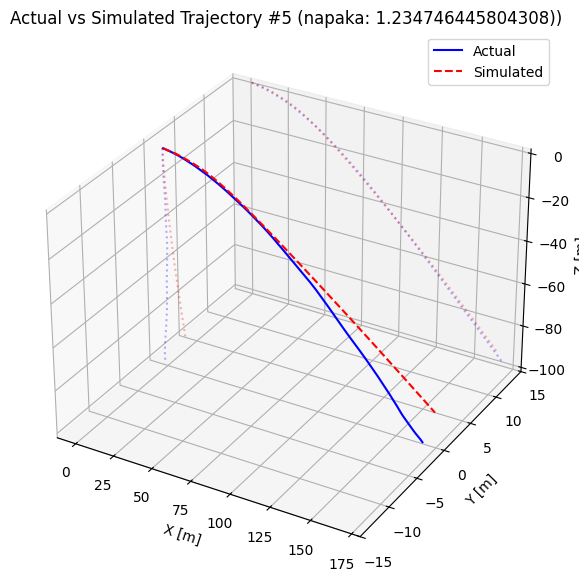

In [96]:
# Pick a jump from TEST set
jump_idx = 4
X_seq_test = X_train[jump_idx]
U_seq_test = U_train[jump_idx]

# Start with the first actual state from the test jump (tensor)
x_pred = [torch.tensor(X_seq_test[0], dtype=torch.float32)]
y_pred = []

# Free-running prediction
for u in U_seq_test[:-1]:
    u_tensor = torch.tensor(u, dtype=torch.float32).unsqueeze(0)
    x_tensor = x_pred[-1].unsqueeze(0)

    next_state, next_obser = model(x_tensor, u_tensor)
    x_pred.append(next_state.squeeze(0).detach())  # still tensor
    y_pred.append(next_obser.squeeze(0).detach())

# Convert to numpy for plotting
x_pred_np = torch.stack(x_pred).numpy()
y_pred_np = torch.stack(y_pred).numpy()

# Extract XYZ from true and predicted
true_xyz = np.array(X_seq_test)[:, :3]
pred_xyz = x_pred_np[:, :3]

# Plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')


Xa = true_xyz[:, 0]
Ya = true_xyz[:, 1]
Za = true_xyz[:, 2]

Xs = pred_xyz[:,0]
Ys = pred_xyz[:,1]
Zs = pred_xyz[:,2]

ax.plot(Xa, Ya, Za, label="Actual", color="blue")
ax.plot(Xs, -Ys, Zs, label="Simulated", color="red", linestyle="--")

# Ground projections
ax.plot(Xa, 15, Za, color="blue", alpha=0.3, linestyle=':')
ax.plot(Xs, 15, Zs, color="red", alpha=0.3, linestyle=':')


ax.plot(0, Ya, Za, color="blue", alpha=0.3, linestyle=':')
ax.plot(0, -Ys, Zs, color="red", alpha=0.3, linestyle=':')

napaka = penalized_bidirectional_distance(actual, sim, 0.5)
napake.append(napaka)



ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.set_title(f"Actual vs Simulated Trajectory #{jump_idx + 1} (napaka: {napaka}))")
ax.set_ylim(-15, 15)
ax.legend()
plt.show()

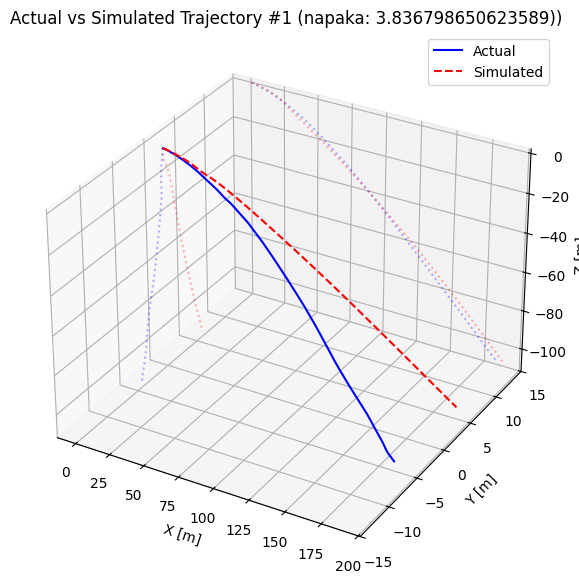

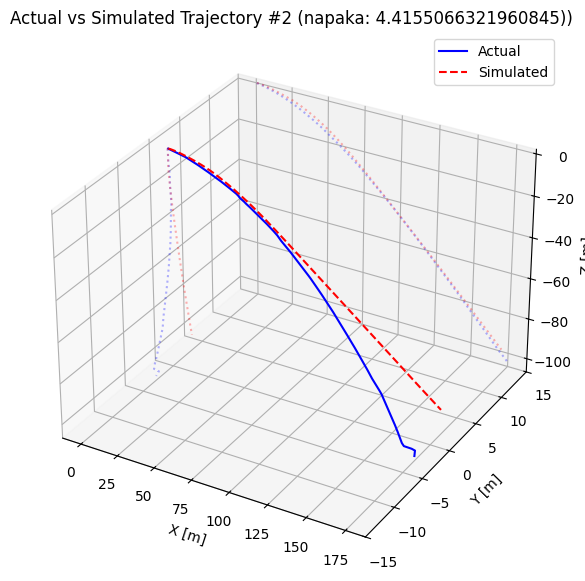

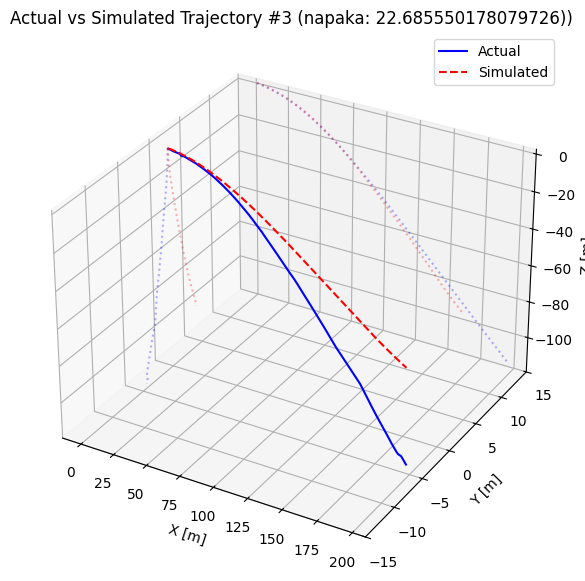

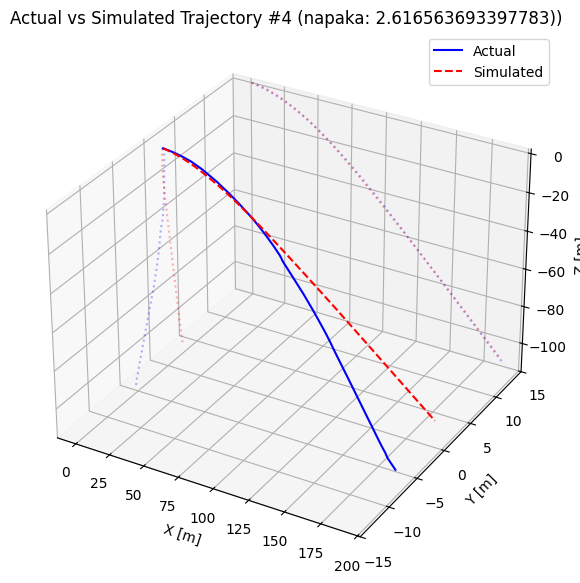

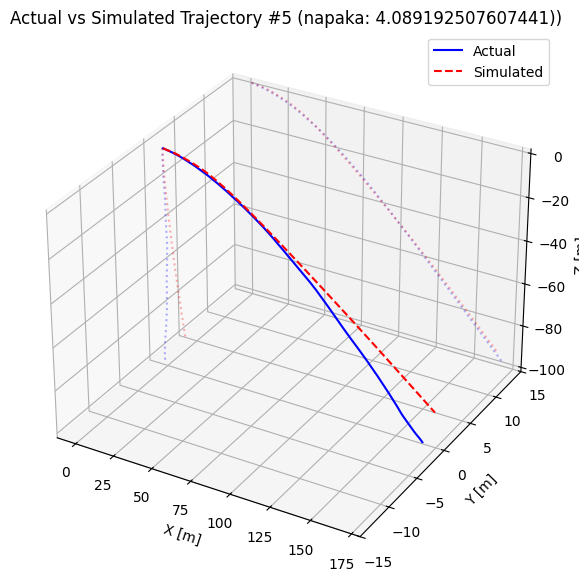

...

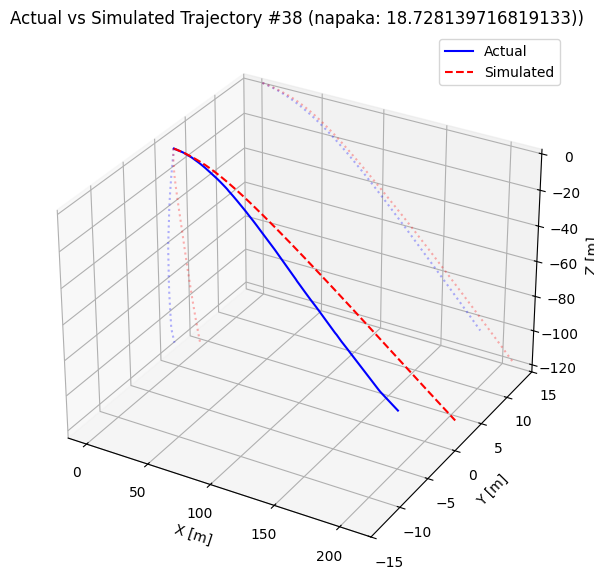

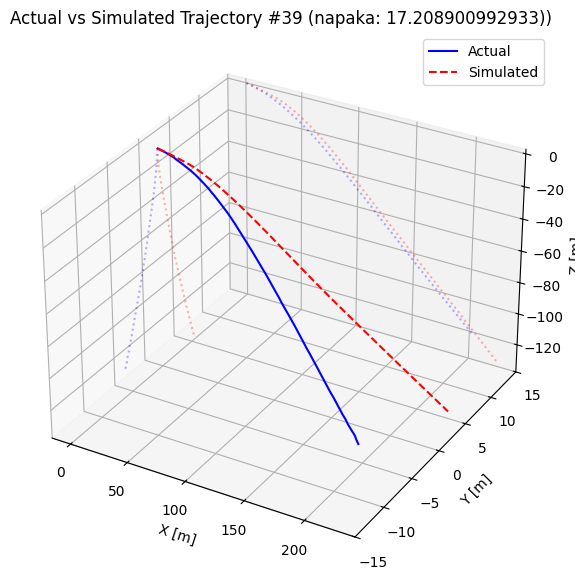

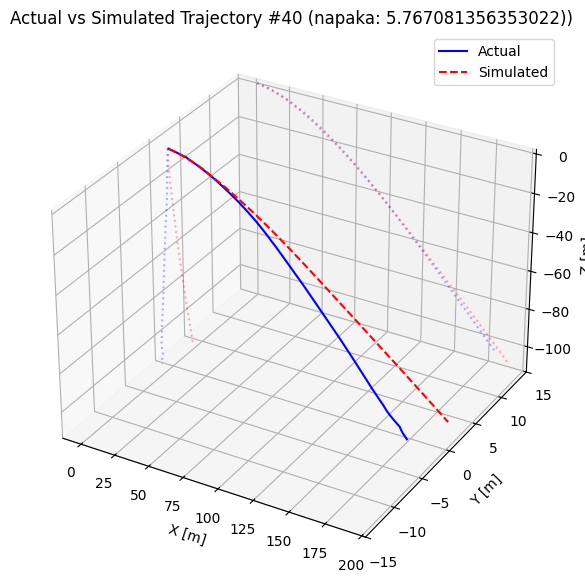

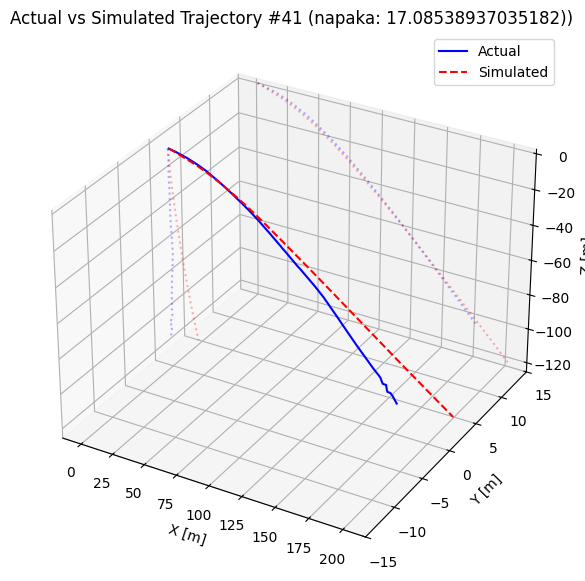

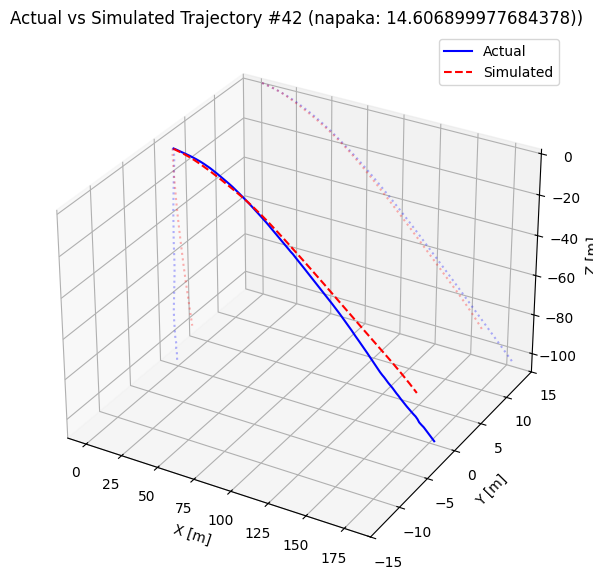

17.8668838316404


In [97]:

save_dir = "plots/simulated/mirroring"
os.makedirs(save_dir, exist_ok=True)

napake= []

for idx in range(len(X_test)):
    # Pick a jump from TEST set
    jump_idx = idx
    X_seq_test = X_train[jump_idx]
    U_seq_test = U_train[jump_idx]

    # Start with the first actual state from the test jump (tensor)
    x_pred = [torch.tensor(X_seq_test[0], dtype=torch.float32)]
    y_pred = []

    # Free-running prediction
    for u in U_seq_test[:-1]:
        u_tensor = torch.tensor(u, dtype=torch.float32).unsqueeze(0)
        x_tensor = x_pred[-1].unsqueeze(0)

        next_state, next_obser = model(x_tensor, u_tensor)
        x_pred.append(next_state.squeeze(0).detach())  # still tensor
        y_pred.append(next_obser.squeeze(0).detach())

    # Convert to numpy for plotting
    x_pred_np = torch.stack(x_pred).numpy()
    y_pred_np = torch.stack(y_pred).numpy()

    # Extract XYZ from true and predicted
    true_xyz = np.array(X_seq_test)[:, :3]
    pred_xyz = x_pred_np[:, :3]

    # Plot
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')


    Xa = true_xyz[:, 0]
    Ya = true_xyz[:, 1]
    Za = true_xyz[:, 2]

    Xs = pred_xyz[:,0]
    Ys = pred_xyz[:,1]
    Zs = pred_xyz[:,2]

    ax.plot(Xa, Ya, Za, label="Actual", color="blue")
    ax.plot(Xs, -Ys, Zs, label="Simulated", color="red", linestyle="--")

    # Ground projections
    ax.plot(Xa, 15, Za, color="blue", alpha=0.3, linestyle=':')
    ax.plot(Xs, 15, Zs, color="red", alpha=0.3, linestyle=':')


    ax.plot(0, Ya, Za, color="blue", alpha=0.3, linestyle=':')
    ax.plot(0, -Ys, Zs, color="red", alpha=0.3, linestyle=':')

    napaka = penalized_bidirectional_distance(true_xyz, pred_xyz, 0.5)
    napake.append(napaka)


    ax.set_ylim(-15, 15)
    ax.set_xlabel("X [m]")
    ax.set_ylabel("Y [m]")
    ax.set_zlabel("Z [m]")
    ax.set_title(f"Actual vs Simulated Trajectory #{jump_idx + 1} (napaka: {napaka}))")
    ax.legend()

    name = f"3pinn_flight_simulation{jump_idx + 1}.png"

    plt.savefig(os.path.join(save_dir, name), dpi=300)

    plt.show()

print(np.average(napake))
    